# Figure 4b
Exact fixation location probability on directed cycles with $N=5$ to $40$ at $r=1$, from a single initial mutant at location 1, given fixation. Data: `python -m fixloc.make.fig4 cycles`.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt

from fixloc import style as S

d = json.load(open('data.json'))

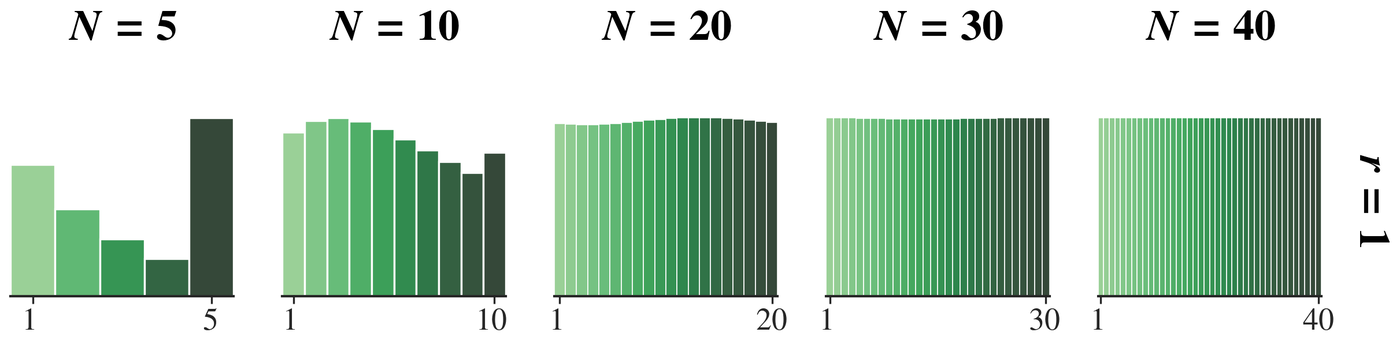

In [2]:
ROW = 0
H_IN = 6.95
y0 = 1 - 2.62 / H_IN
L, RG, GAP = 0.405, 0.945, 0.02
TOP, BOTTOM, ROW_GAP = 0.952, 0.672, 0.022
w = (RG - L - GAP * (len(d['N']) - 1)) / len(d['N'])
h = (TOP - BOTTOM - 2 * ROW_GAP) / 3
yb = TOP - (ROW + 1) * h - ROW * ROW_GAP
fig = plt.figure(figsize=(7.0, H_IN))
for j, (N, p) in enumerate(zip(d['N'], d['P'])):
  p = np.array(p)
  ax = fig.add_axes([L + j * (w + GAP), yb, w, h])
  ax.bar(np.arange(1, N + 1), p, width=1.0, color=[S.CM_CYC(k / (N - 1)) for k in range(N)], edgecolor='white',
         lw=0.4 if N <= 10 else 0.2)
  ax.set_xlim(0.5, N + 0.5)
  ax.set_ylim(0, 1.06 * p.max())
  ax.set_xticks([1, N])
  ax.set_xticklabels([r'$1$', r'$%d$' % N])
  ax.tick_params(axis='x', labelsize=6.5, length=1.5, width=0.4, pad=1)
  ax.set_yticks([])
  for s in ('left', 'right', 'top'):
    ax.spines[s].set_visible(False)
  ax.spines['bottom'].set_linewidth(0.5)
  if ROW == 0:
    fig.text(L + j * (w + GAP) + w / 2, 0.992, r'$\boldsymbol{N = %d}$' % N, ha='center', va='top', fontsize=9)
fig.text(RG + 0.012, yb + h / 2, r'$\boldsymbol{r = %d}$' % d['r'], ha='left', va='center', rotation=-90, fontsize=9)
if ROW == 1:
  fig.text(0.39, BOTTOM + (TOP - BOTTOM) / 2, r'Probability $i$ is fixation location, $p$', ha='center', va='center', rotation=90,
           fontsize=8)
if ROW == 2:
  fig.text(L + (RG - L) / 2, y0 + 0.004, r'Location, $i$', ha='center', va='bottom', fontsize=8)
S.save_panel(fig, 'b')